In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import radians, sin, cos, asin, sqrt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error



In [2]:

df = pd.read_csv("uber.csv")

df


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5
...,...,...,...,...,...,...,...,...,...
199995,42598914,2012-10-28 10:49:00.00000053,3.0,2012-10-28 10:49:00 UTC,-73.987042,40.739367,-73.986525,40.740297,1
199996,16382965,2014-03-14 01:09:00.0000008,7.5,2014-03-14 01:09:00 UTC,-73.984722,40.736837,-74.006672,40.739620,1
199997,27804658,2009-06-29 00:42:00.00000078,30.9,2009-06-29 00:42:00 UTC,-73.986017,40.756487,-73.858957,40.692588,2
199998,20259894,2015-05-20 14:56:25.0000004,14.5,2015-05-20 14:56:25 UTC,-73.997124,40.725452,-73.983215,40.695415,1


In [3]:

df.head()


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [4]:

df.tail()


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
199995,42598914,2012-10-28 10:49:00.00000053,3.0,2012-10-28 10:49:00 UTC,-73.987042,40.739367,-73.986525,40.740297,1
199996,16382965,2014-03-14 01:09:00.0000008,7.5,2014-03-14 01:09:00 UTC,-73.984722,40.736837,-74.006672,40.739620,1
199997,27804658,2009-06-29 00:42:00.00000078,30.9,2009-06-29 00:42:00 UTC,-73.986017,40.756487,-73.858957,40.692588,2
199998,20259894,2015-05-20 14:56:25.0000004,14.5,2015-05-20 14:56:25 UTC,-73.997124,40.725452,-73.983215,40.695415,1
199999,11951496,2010-05-15 04:08:00.00000076,14.1,2010-05-15 04:08:00 UTC,-73.984395,40.720077,-73.985508,40.768793,1


In [5]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


In [6]:

df.describe()


,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [7]:

df.isnull().sum()


Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [8]:

df["fare_amount"].fillna(
    df["fare_amount"].median(), inplace=True
)
df["pickup_longitude"].fillna(
    df["pickup_longitude"].median(), inplace=True
)
df["pickup_latitude"].fillna(
    df["pickup_latitude"].median(), inplace=True
)
df["dropoff_longitude"].fillna(
    df["dropoff_longitude"].median(), inplace=True
)
df["dropoff_latitude"].fillna(
    df["dropoff_latitude"].median(), inplace=True
)
df["passenger_count"].fillna(
    df["passenger_count"].median(), inplace=True
)

df.isnull().sum()


C:\Users\shrad\AppData\Local\Temp\ipykernel_22300\1003734115.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["fare_amount"].fillna(
C:\Users\shrad\AppData\Local\Temp\ipykernel_22300\1003734115.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[co

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64

In [9]:

df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"],
    errors="coerce",
    utc=True
)

df.dtypes


Unnamed: 0                         int64
key                               object
fare_amount                      float64
pickup_datetime      datetime64[ns, UTC]
pickup_longitude                 float64
pickup_latitude                  float64
dropoff_longitude                float64
dropoff_latitude                 float64
passenger_count                    int64
dtype: object

In [10]:

df = df.assign(
    hour=df.pickup_datetime.dt.hour,
    day=df.pickup_datetime.dt.day,
    month=df.pickup_datetime.dt.month,
    year=df.pickup_datetime.dt.year,
    dayofweek=df.pickup_datetime.dt.dayofweek
)

df.head()


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dayofweek
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,2015,3
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2009,4
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,2009,0
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,2009,4
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,2014,3


In [11]:

df = df.drop("pickup_datetime", axis=1)

df.head()


,Unnamed: 0,key,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dayofweek
0,24238194,2015-05-07 19:52:06.0000003,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,2015,3
1,27835199,2009-07-17 20:04:56.0000002,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2009,4
2,44984355,2009-08-24 21:45:00.00000061,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,2009,0
3,25894730,2009-06-26 08:22:21.0000001,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,2009,4
4,17610152,2014-08-28 17:47:00.000000188,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,2014,3


In [12]:

def distanceFormula(latitude1, longitude1, latitude2, longitude2):
    travel_dist = []

    for pos in range(len(latitude1)):
        lat1 = radians(latitude1.iloc[pos])
        lon1 = radians(longitude1.iloc[pos])
        lat2 = radians(latitude2.iloc[pos])
        lon2 = radians(longitude2.iloc[pos])

        dlon = lon2 - lon1
        dlat = lat2 - lat1

        a = (
            sin(dlat / 2) ** 2
            + cos(lat1) * cos(lat2) * sin(dlon / 2) ** 2
        )

        c = 2 * asin(sqrt(a))
        r = 6371

        travel_dist.append(c * r)

    return travel_dist


df["dist_travel_km"] = distanceFormula(
    df["pickup_latitude"],
    df["pickup_longitude"],
    df["dropoff_latitude"],
    df["dropoff_longitude"]
)

df.head()


,Unnamed: 0,key,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dayofweek,dist_travel_km
0,24238194,2015-05-07 19:52:06.0000003,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,2015,3,1.683323
1,27835199,2009-07-17 20:04:56.0000002,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2009,4,2.457590
2,44984355,2009-08-24 21:45:00.00000061,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,2009,0,5.036377
3,25894730,2009-06-26 08:22:21.0000001,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,2009,4,1.661683
4,17610152,2014-08-28 17:47:00.000000188,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,2014,3,4.475450


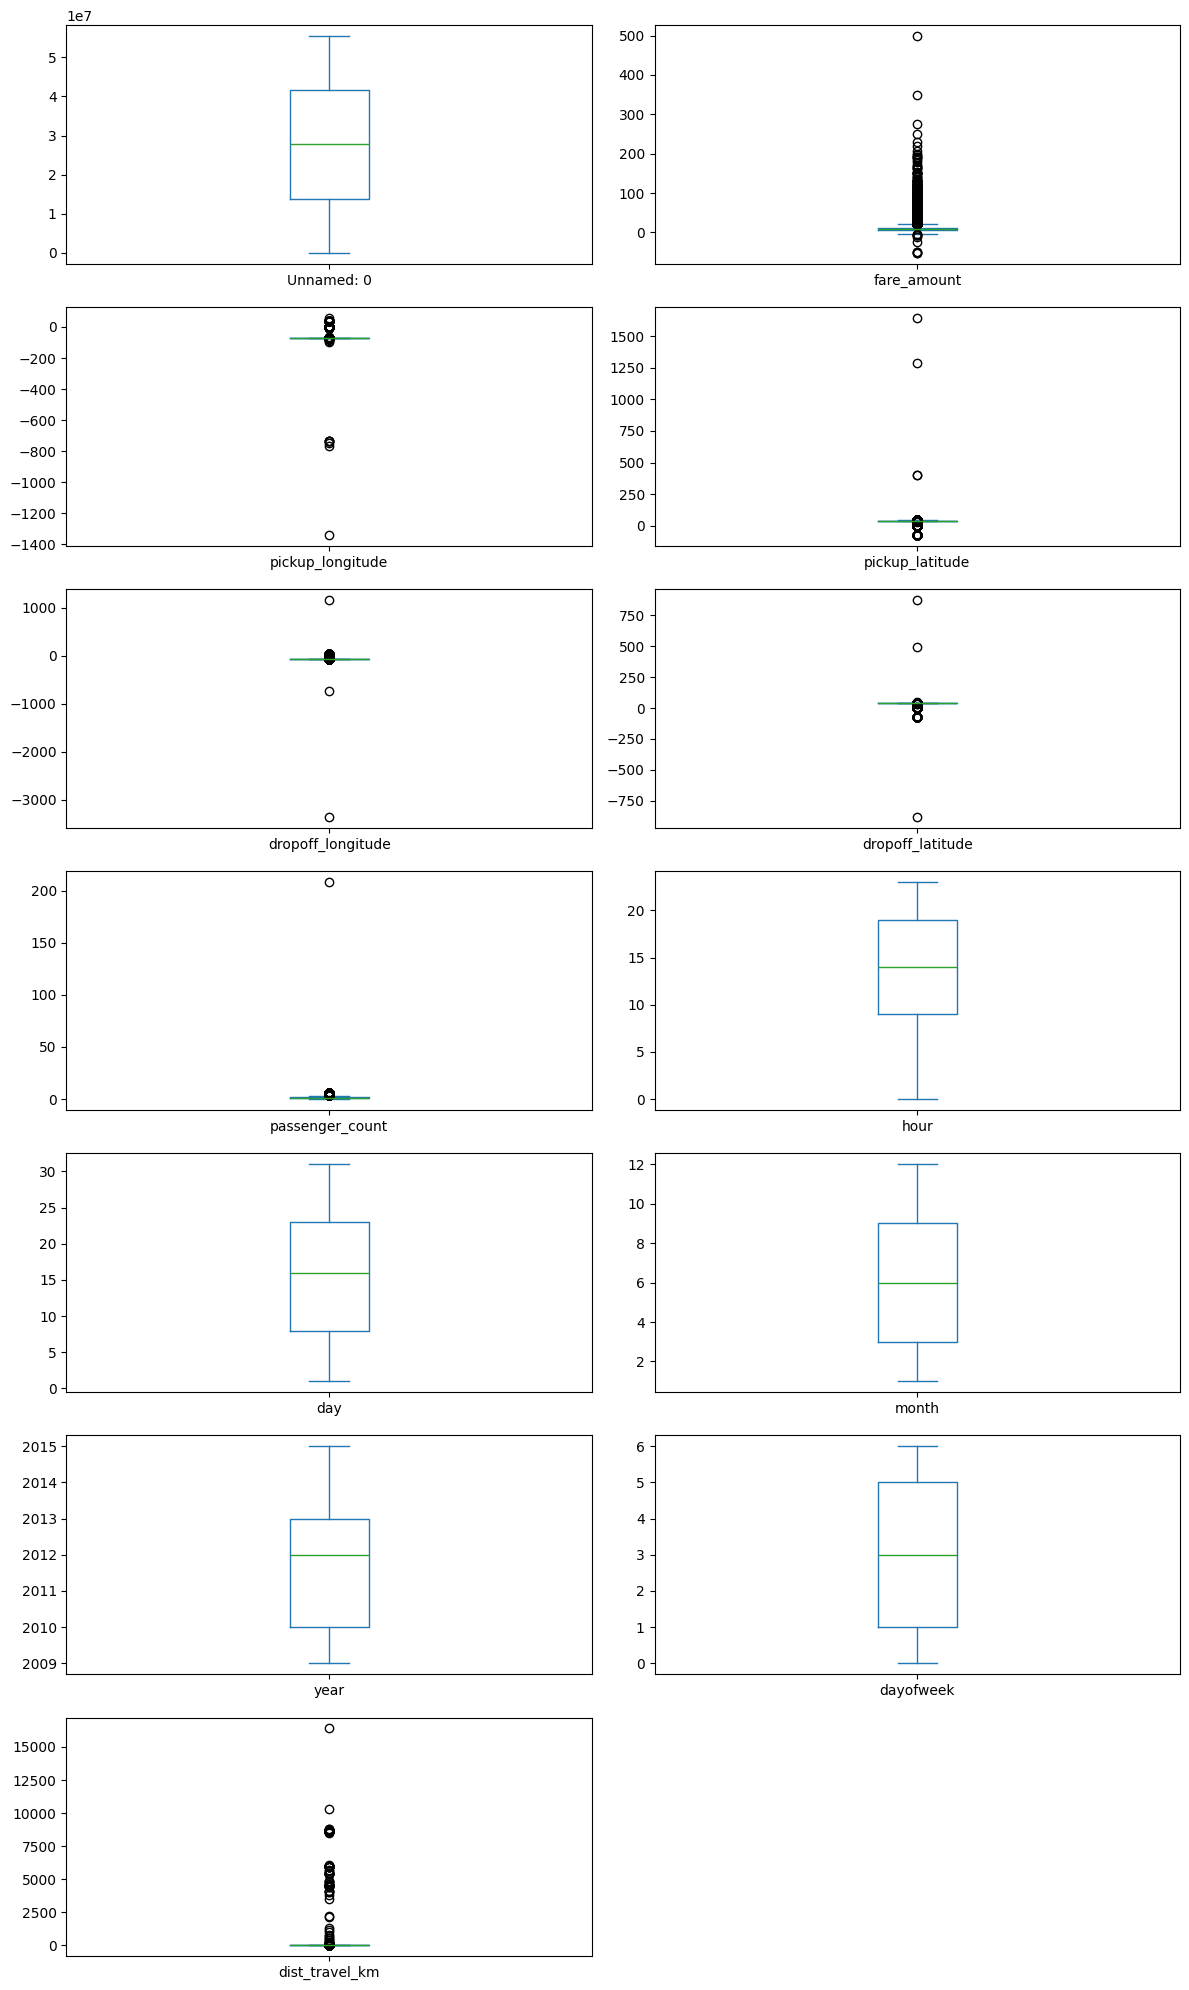

In [13]:

df.plot(
    kind="box",
    subplots=True,
    layout=(7, 2),
    figsize=(12, 20)
)
plt.tight_layout()
plt.show()


In [14]:

def remove_outliers(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_whisker = Q1 - 1.5 * IQR
    upper_whisker = Q3 + 1.5 * IQR

    df[col] = df[col].clip(
        lower=lower_whisker,
        upper=upper_whisker
    )

    return df


def treat_outliers_all(df, col_list):
    for col in col_list:
        df = remove_outliers(df, col)

    return df


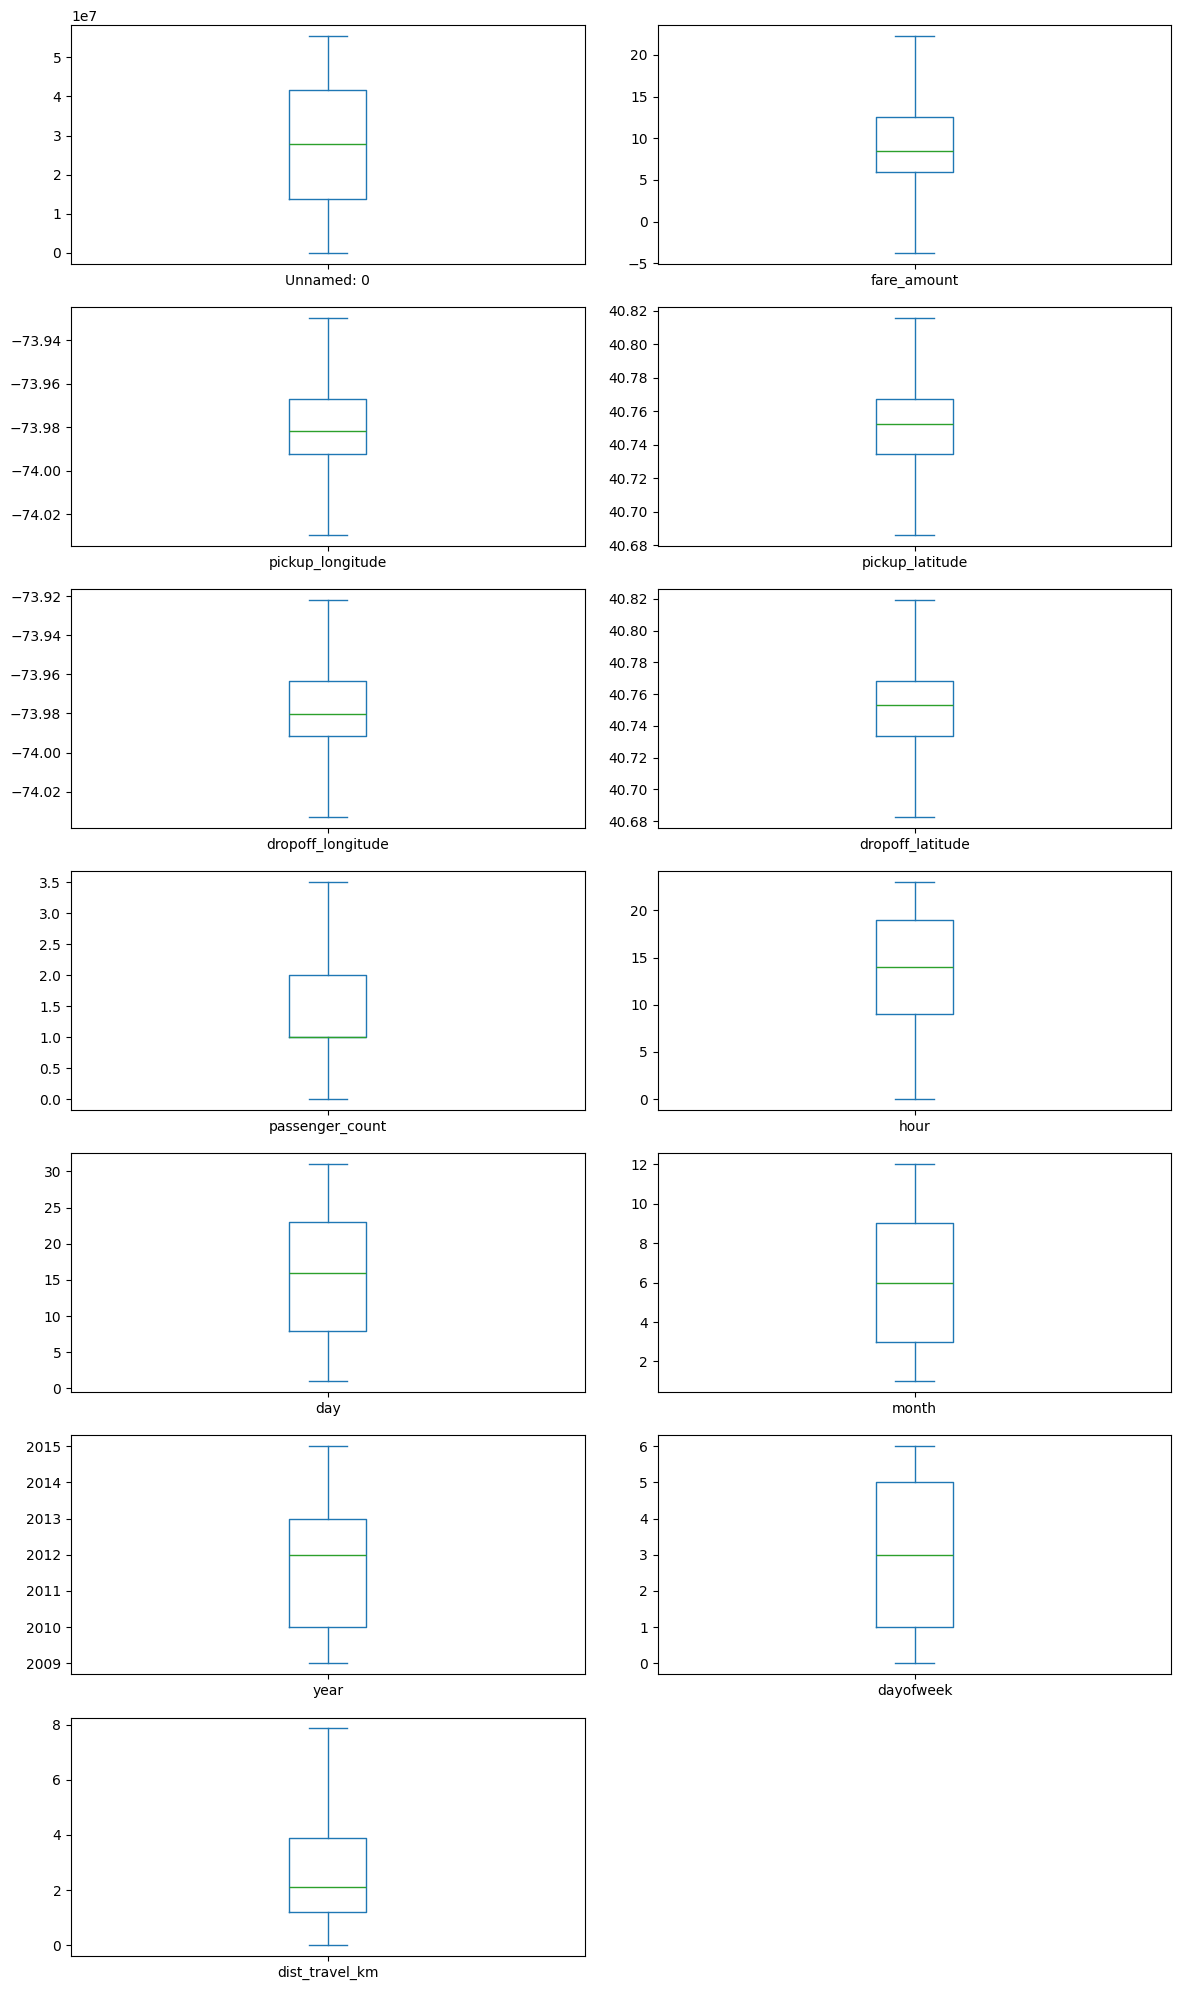

In [15]:

numeric_cols = df.select_dtypes(
    include=["number"]
).columns

df = treat_outliers_all(df, numeric_cols)

df.plot(
    kind="box",
    subplots=True,
    layout=(7, 2),
    figsize=(12, 20)
)

plt.tight_layout()
plt.show()


In [16]:

df.corr(numeric_only=True)


,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dayofweek,dist_travel_km
Unnamed: 0,1.000000,0.000431,0.002570,0.002226,0.006048,0.001119,0.002077,0.000042,0.000554,0.001299,-0.001324,-0.004597,-0.001421
fare_amount,0.000431,1.000000,0.154069,-0.110842,0.218675,-0.125871,0.015778,-0.023623,0.004534,0.030817,0.141277,0.013652,0.844363
pickup_longitude,0.002570,0.154069,1.000000,0.259497,0.425619,0.073311,-0.013213,0.011579,-0.003204,0.001169,0.010198,-0.024652,0.098078
pickup_latitude,0.002226,-0.110842,0.259497,1.000000,0.048889,0.515735,-0.012889,0.029681,-0.001553,0.001562,-0.014243,-0.042310,-0.046821
dropoff_longitude,0.006048,0.218675,0.425619,0.048889,1.000000,0.245674,-0.009303,-0.046558,-0.004007,0.002391,0.011346,-0.003336,0.186531
dropoff_latitude,0.001119,-0.125871,0.073311,0.515735,0.245674,1.000000,-0.006329,0.019764,-0.003499,-0.001190,-0.009595,-0.031932,-0.038873
passenger_count,0.002077,0.015778,-0.013213,-0.012889,-0.009303,-0.006329,1.000000,0.020274,0.002712,0.010351,-0.009749,0.048550,0.009725
hour,0.000042,-0.023623,0.011579,0.029681,-0.046558,0.019764,0.020274,1.000000,0.004677,-0.003926,0.002156,-0.086947,-0.038352
day,0.000554,0.004534,-0.003204,-0.001553,-0.004007,-0.003499,0.002712,0.004677,1.000000,-0.017360,-0.012170,0.005617,0.003076
month,0.001299,0.030817,0.001169,0.001562,0.002391,-0.001190,0.010351,-0.003926,-0.017360,1.000000,-0.115859,-0.008786,0.011626


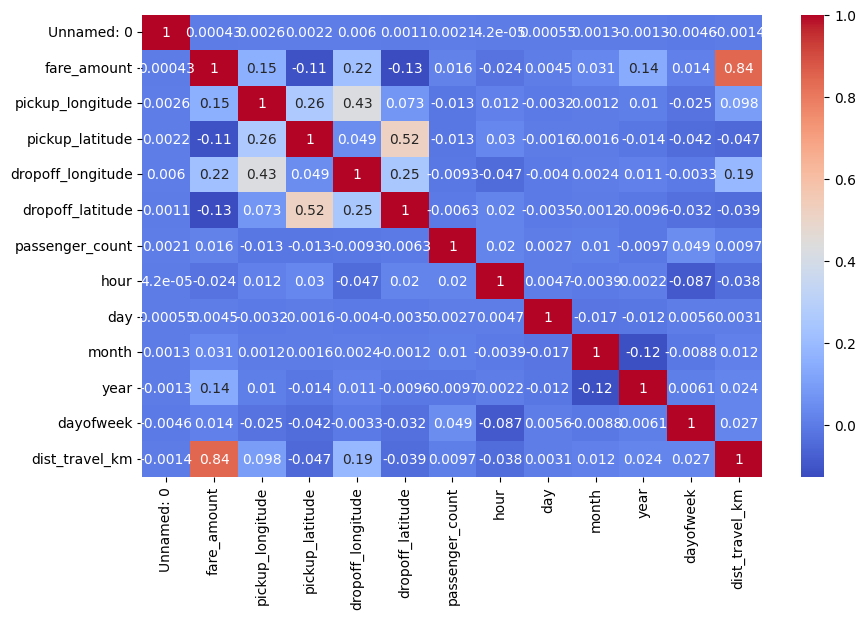

In [17]:

plt.figure(figsize=(10, 6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.show()


In [18]:

X = df[
    [
        "pickup_longitude",
        "pickup_latitude",
        "dropoff_longitude",
        "dropoff_latitude",
        "passenger_count",
        "hour",
        "day",
        "month",
        "year",
        "dayofweek",
        "dist_travel_km"
    ]
]

Y = df["fare_amount"]


In [19]:

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=1
)

X_train.head()


,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dayofweek,dist_travel_km
34297,-73.984999,40.752490,-73.922036,40.768380,2.0,7,20,8,2012,0,7.865037
148120,-73.989357,40.757912,-73.987725,40.740015,1.0,19,20,4,2013,5,1.994799
16583,-73.994345,40.760887,-73.987945,40.735305,1.0,20,14,11,2013,3,2.895229
197713,-73.951972,40.769627,-73.939878,40.809767,1.0,16,31,10,2014,4,4.578020
193997,-74.005842,40.724552,-74.009323,40.710690,1.0,5,3,3,2012,5,1.569055


In [20]:

regression = LinearRegression()

regression.fit(X_train, Y_train)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [21]:

regression.intercept_


np.float64(2696.7849664777013)

In [22]:

regression.coef_


array([ 1.68647031e+01, -9.35554063e+00,  1.46495255e+01, -1.72169712e+01,
        5.84651441e-02,  1.02386704e-02,  2.68527297e-03,  5.62372606e-02,
        3.58512361e-01, -3.21555209e-02,  1.99992599e+00])

In [23]:

Y_test


49673      4.0
171551     6.1
5506       8.5
38370      4.9
36930      6.5
          ... 
63840     10.7
128107     2.5
108940    10.0
199933    11.3
22902     12.5
Name: fare_amount, Length: 40000, dtype: float64

In [ ]:

R2 = r2_score(Y_test, prediction)

MSE = mean_squared_error(Y_test, prediction)

RMSE = np.sqrt(MSE)

print("R2 Score:", R2)
print("Mean Squared Error:", MSE)
print("Root Mean Squared Error:", RMSE)


NameError: name 'prediction' is not defined

In [25]:

rf = RandomForestRegressor(n_estimators=100)

rf.fit(X_train, Y_train)


,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [26]:

Y_pred = rf.predict(X_test)

Y_pred


array([ 5.092,  7.048,  9.545, ..., 11.09 , 11.552, 13.286],
      shape=(40000,))

In [27]:

R2_Random = r2_score(Y_test, Y_pred)

MSE_Random = mean_squared_error(Y_test, Y_pred)

RMSE_Random = np.sqrt(MSE_Random)

print("Random Forest R2 Score:", R2_Random)
print("Random Forest MSE:", MSE_Random)
print("Random Forest RMSE:", RMSE_Random)


Random Forest R2 Score: 0.8123980949127503
Random Forest MSE: 5.573604608978447
Random Forest RMSE: 2.3608482816518404


In [28]:

print("Linear Regression R2 Score:", R2)
print("Random Forest R2 Score:", R2_Random)

print("Linear Regression RMSE:", RMSE)
print("Random Forest RMSE:", RMSE_Random)


NameError: name 'R2' is not defined